# Tugas: Python & Data Analysis
### Studi Kasus: Data Penjualan Toko Parfum Karirnex

Kamu adalah data analyst di toko parfum Karirnex. Data yang dipakai sama dengan hands-on: 10.000 transaksi sepanjang 2025, dari 20 brand dan 6 channel penjualan (harga dalam Rupiah). Manajemen ingin laporan singkat tentang brand mana yang paling menghasilkan.

**Petunjuk:**

- Klik **File > Save a copy in Drive** dulu, sama seperti saat hands-on. Kerjakan tugas di salinan milikmu sendiri.
- Jalankan cell **Setup** paling atas dulu sebelum mengerjakan soal.
- Tulis code kamu di cell yang sudah disediakan, tepat di bawah komentar instruksi.
- Semua soal bisa dikerjakan dengan mencontoh code di notebook hands-on. Di setiap soal ada petunjuk cell mana yang bisa dicontoh.
- Kalau ingin mencetak atau menampilkan sesuatu, gunakan `print()`, contoh `print(df.shape)`. Untuk tabel (DataFrame), cukup tulis nama variable-nya di baris terakhir cell supaya tampil rapi sebagai tabel.
- Boleh pakai Gemini di Colab kalau stuck. Tapi coba sendiri dulu, dan **cek ulang** hasil dari AI.

| No | Soal | Tingkat Kesulitan |
|---|---|---|
| 1 | Kenalan dengan data | Mudah |
| 2 | Jumlah transaksi per brand | Mudah |
| 3 | Metode pembayaran paling populer | Mudah |
| 4 | Cek kualitas data dan ambil transaksi Selesai | Sedang |
| 5 | Brand dengan omzet tertinggi + insight | Sulit |

## Setup

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

url_data = "https://docs.google.com/spreadsheets/d/1NLVLbLKsSZ-phpaJUBP1NQxPyAP79ZUg/export?format=xlsx"
df = pd.read_excel(url_data)

print("Data berhasil di-load! Ukuran:", df.shape)
df.head()

Data berhasil di-load! Ukuran: (10000, 19)


,sales_date,order_id,customer_name,product_name,brand,nama_wangi,jenis_wangi,konsentrasi,gender,size_ml,price,quantity,channel,payment_method,discount,total,shipping_fee,total_sales,status
0,2025-01-01,KRX-PRF000001,Customer_333,Dior Sauvage EDP,Dior,Sauvage,Woody Aromatic,EDP,Pria,60,1800000,2,Online - Marketplace Instaria,QRIS,0.00,3600000,12000,3612000,Selesai
1,2025-01-01,KRX-PRF000002,Customer_5527,Jo Malone English Pear & Freesia Cologne,Jo Malone,English Pear & Freesia,Fruity Floral,Cologne,Unisex,100,2400000,1,Offline - Toko Karirnex,OVO,0.20,1920000,0,1920000,Selesai
2,2025-01-01,KRX-PRF000003,Customer_753,Lattafa Khamrah EDP,Lattafa,Khamrah,Gourmand Oriental,EDP,Unisex,100,650000,2,Offline - Toko Karirnex,QRIS,0.00,1300000,0,1300000,Selesai
3,2025-01-01,KRX-PRF000004,Customer_1564,Versace Bright Crystal EDT,Versace,Bright Crystal,Floral Fruity,EDT,Wanita,90,1100000,1,Offline - Toko Karirnex,Kartu Debit/Kredit,0.05,1045000,0,1045000,Selesai
4,2025-01-01,KRX-PRF000005,Customer_891,Lattafa Khamrah EDP,Lattafa,Khamrah,Gourmand Oriental,EDP,Unisex,100,650000,1,Online - Live Toktok,OVO,0.00,650000,15000,665000,Selesai


**Kalau gagal load:** buka [link data](https://docs.google.com/spreadsheets/d/1NLVLbLKsSZ-phpaJUBP1NQxPyAP79ZUg/edit?usp=sharing), klik **File > Download > Microsoft Excel (.xlsx)**, upload ke Colab lewat ikon folder, lalu ganti `url_data` dengan nama file yang muncul di panel folder, yaitu `"toko_parfum_karirnex_10k.xlsx"`.

## Soal 1: Kenalan dengan Data

Tampilkan:

1. Jumlah baris dan kolom
2. Tipe data tiap kolom (pakai `info()`)
3. 10 baris pertama

*Petunjuk: contoh di hands-on A8.*

In [ ]:
# 1. Jumlah baris dan kolom
df.shape

(10000, 19)

In [ ]:
# 2. Tipe data tiap kolom
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   sales_date      10000 non-null  datetime64[ns]
 1   order_id        10000 non-null  object        
 2   customer_name   10000 non-null  object        
 3   product_name    10000 non-null  object        
 4   brand           10000 non-null  object        
 5   nama_wangi      10000 non-null  object        
 6   jenis_wangi     10000 non-null  object        
 7   konsentrasi     10000 non-null  object        
 8   gender          10000 non-null  object        
 9   size_ml         10000 non-null  int64         
 10  price           10000 non-null  int64         
 11  quantity        10000 non-null  int64         
 12  channel         10000 non-null  object        
 13  payment_method  10000 non-null  object        
 14  discount        10000 non-null  float64       
 15  tot

In [ ]:
# 3. 10 baris pertama
df.head(10)

,sales_date,order_id,customer_name,product_name,brand,nama_wangi,jenis_wangi,konsentrasi,gender,size_ml,price,quantity,channel,payment_method,discount,total,shipping_fee,total_sales,status
0,2025-01-01,KRX-PRF000001,Customer_333,Dior Sauvage EDP,Dior,Sauvage,Woody Aromatic,EDP,Pria,60,1800000,2,Online - Marketplace Instaria,QRIS,0.00,3600000,12000,3612000,Selesai
1,2025-01-01,KRX-PRF000002,Customer_5527,Jo Malone English Pear & Freesia Cologne,Jo Malone,English Pear & Freesia,Fruity Floral,Cologne,Unisex,100,2400000,1,Offline - Toko Karirnex,OVO,0.20,1920000,0,1920000,Selesai
2,2025-01-01,KRX-PRF000003,Customer_753,Lattafa Khamrah EDP,Lattafa,Khamrah,Gourmand Oriental,EDP,Unisex,100,650000,2,Offline - Toko Karirnex,QRIS,0.00,1300000,0,1300000,Selesai
3,2025-01-01,KRX-PRF000004,Customer_1564,Versace Bright Crystal EDT,Versace,Bright Crystal,Floral Fruity,EDT,Wanita,90,1100000,1,Offline - Toko Karirnex,Kartu Debit/Kredit,0.05,1045000,0,1045000,Selesai
4,2025-01-01,KRX-PRF000005,Customer_891,Lattafa Khamrah EDP,Lattafa,Khamrah,Gourmand Oriental,EDP,Unisex,100,650000,1,Online - Live Toktok,OVO,0.00,650000,15000,665000,Selesai
5,2025-01-01,KRX-PRF000006,Customer_25,Yves Saint Laurent Libre EDP,Yves Saint Laurent,Libre,Floral Lavender,EDP,Wanita,50,1700000,1,Online - Website Karirnex,GoPay,0.00,1700000,0,1700000,Selesai
6,2025-01-01,KRX-PRF000007,Customer_3483,Dior Sauvage EDT,Dior,Sauvage,Woody Aromatic,EDT,Pria,100,1950000,1,Online - Marketplace Toko Biru,QRIS,0.00,1950000,0,1950000,Selesai
7,2025-01-01,KRX-PRF000008,Customer_2886,Karirnex Parfums Laut Biru EDT,Karirnex Parfums,Laut Biru,Aquatic Fresh,EDT,Pria,30,109000,1,Online - Marketplace Toko Biru,DANA,0.00,109000,12000,121000,Selesai
8,2025-01-01,KRX-PRF000009,Customer_4990,Versace Bright Crystal EDT,Versace,Bright Crystal,Floral Fruity,EDT,Wanita,90,1100000,1,Online - Marketplace Toko Hijau,GoPay,0.00,1100000,25000,1125000,Selesai
9,2025-01-01,KRX-PRF000010,Customer_5241,Paco Rabanne 1 Million EDT,Paco Rabanne,1 Million,Amber Spicy,EDT,Pria,50,1000000,1,Online - Marketplace Toko Hijau,ShopeePay,0.00,1000000,0,1000000,Selesai


## Soal 2: Jumlah Transaksi per Brand

Hitung jumlah transaksi untuk tiap `brand` dari `df`. Simpan hasil groupby ke variable `transaksi_brand`, lalu tampilkan urut dari yang terbanyak.

*Petunjuk: contoh di hands-on B5. Cukup satu ringkasan di dalam `agg`, yaitu `jumlah_transaksi=("order_id", "count")`. Ganti `df_selesai` jadi `df` dan `"channel"` jadi `"brand"`.*

**Bonus (opsional):** buat bar chart horizontal dari kolom `transaksi_brand["jumlah_transaksi"]`. Contoh di hands-on B6 (baris `.sort_values().plot(kind="barh", ...)`).

In [ ]:
# Groupby brand + agg (jumlah transaksi), simpan ke transaksi_brand, tampilkan urut dari terbanyak
transaksi_brand = df.groupby("brand").agg(
    jumlah_transaksi=("order_id", "count")
).sort_values(by="jumlah_transaksi", ascending=False)

transaksi_brand

,jumlah_transaksi
brand,
Karirnex Parfums,2088
HMNS,1176
Dior,665
Lattafa,603
Victoria's Secret,574
Versace,561
Giorgio Armani,509
Yves Saint Laurent,450
Chanel,396


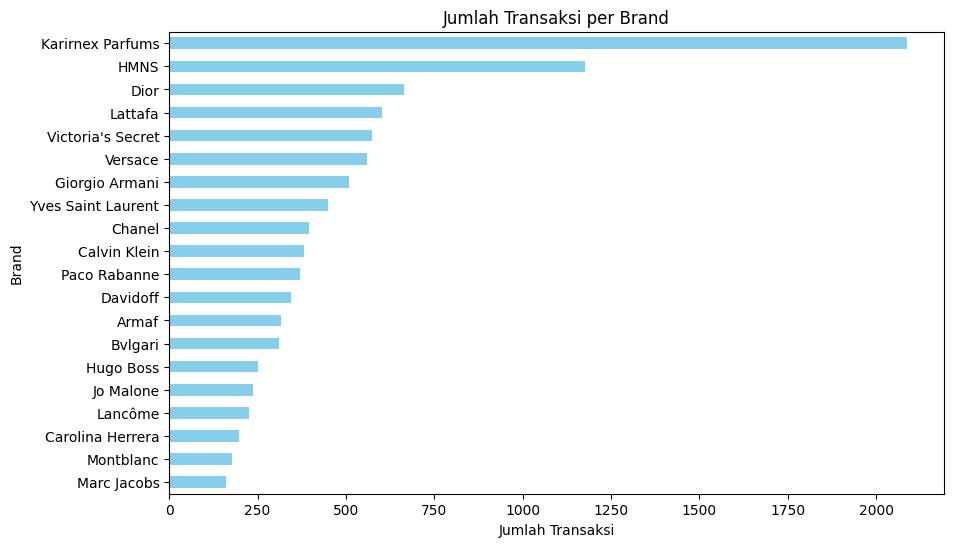

In [ ]:
# (opsional) bar chart horizontal
transaksi_brand["jumlah_transaksi"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color="skyblue",
    title="Jumlah Transaksi per Brand"
)
plt.xlabel("Jumlah Transaksi")
plt.ylabel("Brand")
plt.show()

## Soal 3: Metode Pembayaran Paling Populer

Metode pembayaran (`payment_method`) mana yang paling sering dipakai pembeli? Tampilkan nama metode pembayaran dan jumlah transaksinya.

*Petunjuk: pola yang sama dengan Soal 2, lalu tambahkan `.head(1)` di akhir supaya hanya baris paling atas yang tampil (`head` ada di hands-on A8).*

In [ ]:
# Hitung jumlah transaksi per payment_method, urutkan dari terbanyak, tampilkan yang teratas
transaksi_pembayaran = df.groupby("payment_method").agg(
    jumlah_transaksi=("order_id", "count")
).sort_values(by="jumlah_transaksi", ascending=False).head(1)

transaksi_pembayaran

,jumlah_transaksi
payment_method,
Kartu Debit/Kredit,2366


## Soal 4: Cek Kualitas Data dan Ambil Transaksi Selesai

Sebelum menghitung omzet, pastikan datanya aman dipakai:

1. Cek jumlah **missing value** per kolom dan jumlah **baris duplikat**. *(hands-on B1)*
2. Hitung jumlah transaksi per `status`, urutkan dari yang terbanyak. *(pola Soal 2)*
3. Ambil hanya transaksi dengan `status` = `"Selesai"`, simpan ke `df_selesai`, lalu tampilkan ukurannya dengan `print(df_selesai.shape)`. *(hands-on B2)*

In [ ]:
# 1. Cek missing value dan duplikat
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

Missing value per kolom:
sales_date        0
order_id          0
customer_name     0
product_name      0
brand             0
nama_wangi        0
jenis_wangi       0
konsentrasi       0
gender            0
size_ml           0
price             0
quantity          0
channel           0
payment_method    0
discount          0
total             0
shipping_fee      0
total_sales       0
status            0
dtype: int64

Jumlah baris duplikat: 0


In [ ]:
# 2. Jumlah transaksi per status
transaksi_status = df.groupby("status").agg(
    jumlah_transaksi=("order_id", "count")
).sort_values(by="jumlah_transaksi", ascending=False)

transaksi_status

,jumlah_transaksi
status,
Selesai,9170
Retur (Produk Rusak/Tidak Sesuai),436
Dibatalkan,394


In [ ]:
# 3. Filter status Selesai, simpan ke df_selesai, tampilkan shape-nya
df_selesai = df[df["status"] == "Selesai"]
print(df_selesai.shape)

(9170, 19)


## Soal 5: Brand dengan Omzet Tertinggi

Manajemen ingin tahu brand mana yang paling besar omzetnya. Omzet memakai kolom `total` dan hanya dari transaksi Selesai, jadi pakai `df_selesai` dari Soal 4.

1. Groupby `brand` lalu pakai `agg` untuk menghitung **jumlah transaksi** (`order_id`, `count`) dan **omzet** (`total`, `sum`). Urutkan dari omzet terbesar. *(hands-on B5)*
2. Buat bar chart horizontal **10 brand dengan omzet terbesar**, dalam juta Rupiah. *(hands-on B6: ganti `"product_name"` jadi `"brand"` dan `head(5)` jadi `head(10)`)*
3. Tulis **1 insight bisnis** (1-2 kalimat) di cell teks di bawahnya. Coba bandingkan hasilnya dengan Soal 2: apakah brand dengan transaksi terbanyak juga punya omzet terbesar?

In [ ]:
# 1. Groupby brand + agg (jumlah transaksi, omzet), urutkan dari omzet terbesar
omzet_brand = df_selesai.groupby("brand").agg(
    jumlah_transaksi=("order_id", "count"),
    omzet=("total", "sum")
).sort_values(by="omzet", ascending=False)

omzet_brand

,jumlah_transaksi,omzet
brand,,
Dior,612,1111475500
Chanel,359,935670000
Yves Saint Laurent,410,766512500
Giorgio Armani,460,664885000
Versace,516,515436000
Karirnex Parfums,1916,493445200
Paco Rabanne,336,430489500
Jo Malone,216,396710000
Lancôme,209,382108500


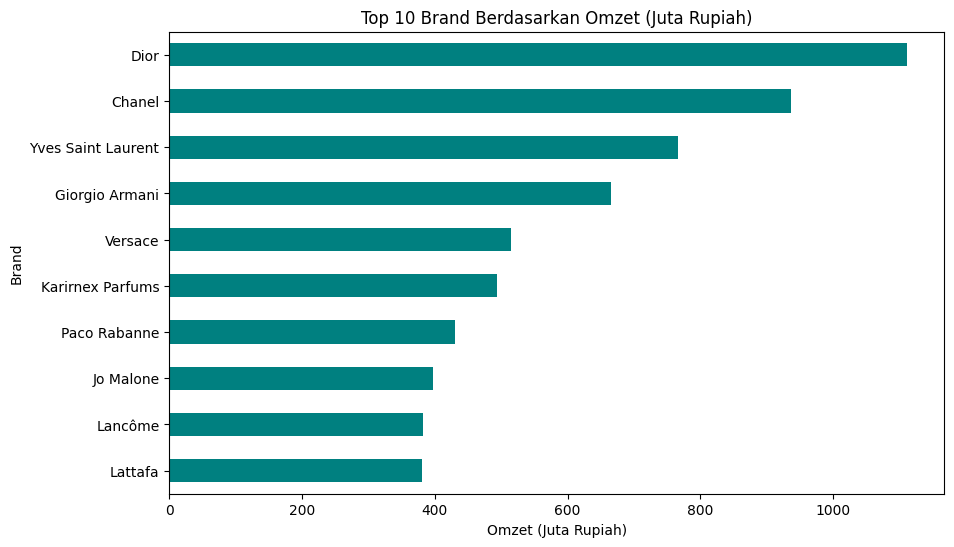

In [ ]:
# 2. Bar chart horizontal top 10 brand berdasarkan omzet (juta Rupiah)
# Konversi omzet ke juta Rupiah dengan membagi 1.000.000
(omzet_brand["omzet"].head(10) / 1000000).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color="teal",
    title="Top 10 Brand Berdasarkan Omzet (Juta Rupiah)"
)
plt.xlabel("Omzet (Juta Rupiah)")
plt.ylabel("Brand")
plt.show()

### Insight

1.  Brand dengan transaksi terbanyak belum tentu menghasilkan omzet terbesar: Karirnex Parfums unggul di jumlah transaksi (1.916, atau 20,9% dari total) tetapi hanya menyumbang 5,9% omzet, sedangkan Dior memimpin omzet (Rp1,11 miliar) dengan hanya 612 transaksi. Penyebabnya adalah selisih harga rata-rata per transaksi, yaitu ±Rp1,8 juta untuk Dior dibandingkan ±Rp257 ribu untuk Karirnex Parfums, sehingga brand premium lebih menentukan omzet daripada brand dengan volume tinggi.

